# 4. Modelo base

## 4.1 Variable objetivo, partición, validación y búsqueda de `C`

- **Variable objetivo:** $y = 1$ si el cliente suscribió el depósito a término (`yes`) y $y = 0$ en caso contrario.
- **Partición:** cronológica 80/20 (sección 2), definida antes de cualquier preprocesamiento: el entrenamiento es el primer 80 % de los registros en orden temporal y la prueba, el último 20 %.
- **Validación cruzada:** del mismo tipo que la partición: `TimeSeriesSplit` de cinco pliegues sobre el entrenamiento ordenado, con separación de un día de contactos (sección 3).
- **Modelo:** regresión logística con penalización L2 dentro del `Pipeline` de la sección 3.7. El hiperparámetro de regularización `C` se elige con la validación temporal, maximizando el AUC promedio de los pliegues.
- **Línea base trivial:** `DummyClassifier(strategy="prior")`, que predice siempre la clase mayoritaria y asigna a todos la misma probabilidad (la prevalencia de entrenamiento).
- **Conjunto de prueba:** se usa una sola vez, en la sección 4.4.

La primera tabla muestra la búsqueda de `C` y la segunda, el resultado de cada pliegue con el valor elegido.

In [34]:
from sklearn.metrics import make_scorer
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf

ESCORES = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
           "recall": make_scorer(recall_score, zero_division=0), "f1": make_scorer(f1_score, zero_division=0),
           "auc": "roc_auc", "auc_pr": "average_precision"}
NOMBRES_M = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1", "auc": "AUC",
             "auc_pr": "AUC-PR"}

grid = GridSearchCV(construir_modelo(), {"lr__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}, cv=tss,
                    scoring={"auc": "roc_auc", "auc_pr": "average_precision"}, refit="auc", return_train_score=True)
grid.fit(X_tr, y_tr)
C_opt = grid.best_params_["lr__C"]
res_grid = pd.DataFrame(grid.cv_results_)
busqueda = pd.DataFrame({
    "C": [num_c(c) for c in res_grid["param_lr__C"].astype(float)],
    "AUC validación (media)": res_grid["mean_test_auc"], "AUC validación (desv. est.)": res_grid["std_test_auc"],
    "AUC entrenamiento (media)": res_grid["mean_train_auc"], "AUC-PR validación (media)": res_grid["mean_test_auc_pr"]})
tabla(busqueda.set_index("C"), dec=4)

i_opt = grid.best_index_
pliegues_opt = esquema_tss[["Valida desde", "Valida hasta", "% positivos (validación)"]].copy()
pliegues_opt["AUC"] = [res_grid.loc[i_opt, f"split{k}_test_auc"] for k in range(len(pliegues_opt))]
pliegues_opt["AUC-PR"] = [res_grid.loc[i_opt, f"split{k}_test_auc_pr"] for k in range(len(pliegues_opt))]
tabla(pliegues_opt, dec=3)

rango_auc = busqueda["AUC validación (media)"].max() - busqueda["AUC validación (media)"].min()
brecha = res_grid.loc[i_opt, "mean_train_auc"] - res_grid.loc[i_opt, "mean_test_auc"]
es_2008 = pliegues_opt["Valida hasta"].str.startswith("2008")
auc_2008 = pliegues_opt.loc[es_2008, "AUC"].mean()
auc_ultimo = pliegues_opt["AUC"].iloc[-1]
interpretar(
    f"El mejor valor es C = {num_c(C_opt)}, con AUC de validación temporal de {num(grid.best_score_, 4)} (desviación "
    f"entre pliegues de {num(res_grid.loc[i_opt, 'std_test_auc'], 4)}); entre todos los valores de C el AUC varía "
    f"{num(rango_auc, 4)}. Por pliegue, el AUC va de {num(pliegues_opt['AUC'].min(), 3)} a "
    f"{num(pliegues_opt['AUC'].max(), 3)}: los {int(es_2008.sum())} pliegues que validan en 2008 promedian "
    f"{num(auc_2008, 3)} y el último ({pliegues_opt['Valida desde'].iloc[-1]} a {pliegues_opt['Valida hasta'].iloc[-1]}) "
    f"llega a {num(auc_ultimo, 3)}. La diferencia entre el AUC de entrenamiento y el de validación es de {num(brecha, 4)}.",
    f"Con {num(y_tr.sum())} eventos y {len(nombres_salida)} columnas, la brecha no se explica por exceso de parámetros "
    "sino por el cambio de condiciones entre el periodo de ajuste y el de validación. "
    + ("Dentro de 2008 el modelo casi no logra ordenar a los clientes del bloque siguiente"
       if auc_2008 < 0.6 else "Dentro de 2008 el modelo ordena de forma limitada a los clientes del bloque siguiente")
    + (", y la señal aparece cuando la validación incluye meses de 2009. " if auc_ultimo > auc_2008 + 0.05 else ". ")
    + "La elección de C pesa poco frente a ese efecto.",
    f"Fijar C = {num_c(C_opt)} para el modelo base y leer las métricas de validación como una estimación "
    "conservadora y variable del desempeño en periodos futuros.")

,AUC validación (media),AUC validación (desv. est.),AUC entrenamiento (media),AUC-PR validación (media)
C,,,,
"0,001","0,5058","0,0738","0,5851","0,0906"
"0,01","0,5139","0,0869","0,5972","0,0968"
"0,1","0,5217","0,0887","0,6121","0,0956"
1,"0,5374","0,0753","0,6166","0,0961"
10,"0,5418","0,0744","0,6170","0,0975"
100,"0,5422","0,0740","0,6170","0,0972"


,Valida desde,Valida hasta,% positivos (validación),AUC,AUC-PR
Pliegue,,,,,
1,2008-05,2008-06,"3,880","0,518","0,041"
2,2008-06,2008-07,"6,047","0,522","0,065"
3,2008-07,2008-08,"5,920","0,488","0,060"
4,2008-08,2008-11,"5,446","0,495","0,055"
5,2008-11,2009-05,"14,026","0,688","0,265"


**Lectura.** El mejor valor es C = 100, con AUC de validación temporal de 0,5422 (desviación entre pliegues de 0,0740); entre todos los valores de C el AUC varía 0,0364. Por pliegue, el AUC va de 0,488 a 0,688: los 4 pliegues que validan en 2008 promedian 0,506 y el último (2008-11 a 2009-05) llega a 0,688. La diferencia entre el AUC de entrenamiento y el de validación es de 0,0748.

**Implicación predictiva.** Con 2 100 eventos y 49 columnas, la brecha no se explica por exceso de parámetros sino por el cambio de condiciones entre el periodo de ajuste y el de validación. Dentro de 2008 el modelo casi no logra ordenar a los clientes del bloque siguiente, y la señal aparece cuando la validación incluye meses de 2009. La elección de C pesa poco frente a ese efecto.

**Acción recomendada.** Fijar C = 100 para el modelo base y leer las métricas de validación como una estimación conservadora y variable del desempeño en periodos futuros.

## 4.2 Comparación con la línea base trivial en validación temporal

Antes de tocar el conjunto de prueba, se comparan el `DummyClassifier` y la regresión logística con las mismas métricas y los mismos pliegues temporales (umbral de clasificación 0,5).

In [35]:
def predicciones_validacion(modelo, X, y, cv):
    """Probabilidades de validación de cada pliegue temporal (solo entrenamiento), concatenadas."""
    indices, probs = [], []
    for i_ent, i_val in cv.split(X):
        m_ = clone(modelo).fit(X.iloc[i_ent], y.iloc[i_ent])
        indices.append(i_val)
        probs.append(m_.predict_proba(X.iloc[i_val])[:, 1])
    return np.concatenate(indices), np.concatenate(probs)


dummy = DummyClassifier(strategy="prior")
cv_d = cross_validate(dummy, X_tr, y_tr, cv=tss, scoring=ESCORES)
cv_m = cross_validate(construir_modelo(C=C_opt), X_tr, y_tr, cv=tss, scoring=ESCORES)
comp_cv = pd.DataFrame({
    "Dummy (media)": [cv_d[f"test_{m}"].mean() for m in ESCORES],
    "Regresión logística (media)": [cv_m[f"test_{m}"].mean() for m in ESCORES],
    "Regresión logística (desv. est.)": [cv_m[f"test_{m}"].std() for m in ESCORES]},
    index=[NOMBRES_M[m] for m in ESCORES])
comp_cv["Diferencia"] = comp_cv["Regresión logística (media)"] - comp_cv["Dummy (media)"]
tabla(comp_cv, dec=4)
idx_val, prob_val = predicciones_validacion(construir_modelo(C=C_opt), X_tr, y_tr, tss)

interpretar(
    f"En validación temporal, el Dummy obtiene accuracy de {num(comp_cv.loc['Accuracy', 'Dummy (media)'], 3)} sin "
    f"identificar a ningún cliente que suscribe. La regresión logística con umbral 0,5 llega a accuracy de "
    f"{num(comp_cv.loc['Accuracy', 'Regresión logística (media)'], 3)} (diferencia de "
    f"{num(comp_cv.loc['Accuracy', 'Diferencia'], 3)}), AUC de {num(comp_cv.loc['AUC', 'Regresión logística (media)'], 3)} "
    f"frente a 0,5 y AUC-PR de {num(comp_cv.loc['AUC-PR', 'Regresión logística (media)'], 3)} frente a "
    f"{num(comp_cv.loc['AUC-PR', 'Dummy (media)'], 3)}. Con umbral 0,5 el recall es "
    f"{num(comp_cv.loc['Recall', 'Regresión logística (media)'], 3)}: solo el {pct((prob_val >= 0.5).mean())} de las "
    "probabilidades de validación supera 0,5.",
    "El accuracy apenas distingue un modelo útil de uno trivial; la mejora del modelo, cuando existe, se ve en AUC y "
    "AUC-PR. Con una prevalencia de entrenamiento baja, el modelo rara vez asigna probabilidades mayores a 0,5, así "
    "que ese umbral deja escapar a casi todos los que suscriben.",
    "Elegir el umbral de decisión con la validación temporal del entrenamiento (sección 4.3), en lugar de usar 0,5.")

,Dummy (media),Regresión logística (media),Regresión logística (desv. est.),Diferencia
Accuracy,"0,9294","0,8695","0,1546","-0,0598"
Precision,"0,0000","0,0415","0,0830","0,0415"
Recall,"0,0000","0,1514","0,3029","0,1514"
F1,"0,0000","0,0652","0,1304","0,0652"
AUC,"0,5000","0,5422","0,0740","0,0422"
AUC-PR,"0,0706","0,0972","0,0841","0,0266"


**Lectura.** En validación temporal, el Dummy obtiene accuracy de 0,929 sin identificar a ningún cliente que suscribe. La regresión logística con umbral 0,5 llega a accuracy de 0,870 (diferencia de -0,060), AUC de 0,542 frente a 0,5 y AUC-PR de 0,097 frente a 0,071. Con umbral 0,5 el recall es 0,151: solo el 10,2 % de las probabilidades de validación supera 0,5.

**Implicación predictiva.** El accuracy apenas distingue un modelo útil de uno trivial; la mejora del modelo, cuando existe, se ve en AUC y AUC-PR. Con una prevalencia de entrenamiento baja, el modelo rara vez asigna probabilidades mayores a 0,5, así que ese umbral deja escapar a casi todos los que suscriben.

**Acción recomendada.** Elegir el umbral de decisión con la validación temporal del entrenamiento (sección 4.3), en lugar de usar 0,5.

## 4.3 Umbral de decisión

Sin una matriz de costos de la campaña, se usa el umbral que maximiza el F1. Como la prevalencia y el contexto económico cambian en el tiempo (sección 3.6), el umbral se elige con el pliegue de validación temporal más reciente del entrenamiento, el más parecido al periodo siguiente, y no con el promedio de los pliegues, dominado por bloques de 2008 con otra prevalencia (sección 3). El umbral se fijó solo con datos de entrenamiento.

In [36]:
rejilla_u = np.round(np.linspace(0.01, 0.90, 90), 2)
i_ent_rec, i_val_rec = list(tss.split(X_tr))[-1]
ajuste_umbral = TunedThresholdClassifierCV(construir_modelo(C=C_opt), scoring="f1", cv=[(i_ent_rec, i_val_rec)],
                                           thresholds=rejilla_u, store_cv_results=True).fit(X_tr, y_tr)
umbral = float(ajuste_umbral.best_threshold_)
modelo_final = ajuste_umbral.estimator_   # Pipeline reajustado con todo el entrenamiento
f1_05_rec = np.interp(0.5, ajuste_umbral.cv_results_["thresholds"], ajuste_umbral.cv_results_["scores"])
print(f"Pliegue más reciente: {periodo_tr.iloc[i_val_rec[0]]} a {periodo_tr.iloc[i_val_rec[-1]]} · umbral elegido = "
      f"{num(umbral, 2)} (F1 = {num(ajuste_umbral.best_score_, 3)}; con 0,5 el F1 sería {num(f1_05_rec, 3)})")

Pliegue más reciente: 2008-11 a 2009-05 · umbral elegido = 0,60 (F1 = 0,328; con 0,5 el F1 sería 0,326)


## 4.4 Métricas en el conjunto de prueba con intervalos de confianza

Se evalúan una sola vez, en prueba, el `DummyClassifier`, la regresión logística con umbral 0,5 y la regresión logística con el umbral elegido en la sección 4.3. Los intervalos de confianza del 95 % se obtienen con *bootstrap* percentil de 1 000 remuestras **por bloques de día** (Efron y Tibshirani, 1993): se remuestrean con reposición los días de contacto del periodo de prueba (`SEED`) y se conservan juntos los contactos de un mismo día, porque comparten condiciones y sus resultados están correlacionados (sección 4.10); un *bootstrap* registro por registro subestimaría la incertidumbre. Se usan las mismas remuestras para todos los modelos, lo que permite calcular también intervalos para las diferencias frente a la línea base.

In [37]:
dummy_ajustado = DummyClassifier(strategy="prior").fit(X_tr, y_tr)
prob_te = modelo_final.predict_proba(X_te)[:, 1]
prob_dummy = dummy_ajustado.predict_proba(X_te)[:, 1]
pred_dummy = dummy_ajustado.predict(X_te)
pred_05 = (prob_te >= 0.5).astype(int)
pred_u = ajuste_umbral.predict(X_te)
yv = y_te.to_numpy()
assert np.array_equal(pred_u, (prob_te >= umbral).astype(int))

METRICAS = ["Accuracy", "Precision", "Recall", "F1", "AUC", "AUC-PR", "Brier"]


def metricas(y, prob, pred):
    tp = np.sum((pred == 1) & (y == 1))
    fp = np.sum((pred == 1) & (y == 0))
    fn = np.sum((pred == 0) & (y == 1))
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return np.array([np.mean(pred == y), prec, rec, f1, roc_auc_score(y, prob), average_precision_score(y, prob),
                     np.mean((prob - y) ** 2)])


nombre_05 = "Regresión logística, umbral 0,5"
nombre_u = f"Regresión logística, umbral {num(umbral, 2)}"
modelos_eval = {"Dummy (prior)": (prob_dummy, pred_dummy), nombre_05: (prob_te, pred_05), nombre_u: (prob_te, pred_u)}
puntual = {k: metricas(yv, *v) for k, v in modelos_eval.items()}
assert np.isclose(puntual[nombre_05][3], f1_score(yv, pred_05))
assert np.isclose(puntual[nombre_05][6], brier_score_loss(yv, prob_te))

# Bootstrap por bloques de día (X_te conserva el orden temporal)
_, grupo_dia = np.unique(dia_te.to_numpy(), return_inverse=True)
bloques = [np.flatnonzero(grupo_dia == g) for g in range(grupo_dia.max() + 1)]
B = 1000
rng_boot = np.random.default_rng(SEED)
remuestras = [np.concatenate([bloques[g] for g in rng_boot.integers(0, len(bloques), size=len(bloques))])
              for _ in range(B)]
boot = {k: np.array([metricas(yv[ii], v[0][ii], v[1][ii]) for ii in remuestras]) for k, v in modelos_eval.items()}
print(f"Bootstrap: {B} remuestras de los {len(bloques)} días de contacto de la prueba "
      f"(mediana de {num(np.median([len(b) for b in bloques]))} registros por día).")


def con_ic(valor, muestras):
    lo, hi = np.percentile(muestras, [2.5, 97.5])
    return f"{num(valor, 3)} [{num(lo, 3)}; {num(hi, 3)}]"


tabla_test = pd.DataFrame({k: [con_ic(puntual[k][j], boot[k][:, j]) for j in range(len(METRICAS))]
                           for k in modelos_eval}, index=METRICAS).T
display(Markdown("**Métricas en prueba: valor puntual [IC 95 % bootstrap por bloques de día]**"))
tabla(tabla_test)

d_u = boot[nombre_u] - boot["Dummy (prior)"]
excluye_cero = all(np.percentile(d_u[:, METRICAS.index(m)], 2.5) > 0 for m in ["AUC", "AUC-PR", "Recall", "F1"])
difs = {}
for k in [nombre_05, nombre_u]:
    d = boot[k] - boot["Dummy (prior)"]
    difs[k] = [con_ic(puntual[k][j] - puntual["Dummy (prior)"][j], d[:, j]) for j in range(len(METRICAS))]
tabla_dif = pd.DataFrame(difs, index=METRICAS).T
display(Markdown("**Diferencia frente al Dummy (modelo − Dummy) [IC 95 % bootstrap pareado por bloques de día]**"))
tabla(tabla_dif)

P = {k: dict(zip(METRICAS, v)) for k, v in puntual.items()}
IC = {k: {m: np.percentile(boot[k][:, j], [2.5, 97.5]) for j, m in enumerate(METRICAS)} for k in boot}
prev_te = yv.mean()
marcados_u = pred_u.mean()
acc_m, acc_u, acc_d = P[nombre_05]["Accuracy"], P[nombre_u]["Accuracy"], P["Dummy (prior)"]["Accuracy"]


def frente_dummy(a):
    return "por debajo del" if a < acc_d - 0.005 else ("prácticamente igual al" if abs(a - acc_d) <= 0.005 else "por encima del")


interpretar(
    f"En prueba suscribe el {pct(prev_te)}. El Dummy obtiene accuracy de {num(acc_d, 3)} con recall y F1 de cero, "
    f"AUC de 0,5 y AUC-PR de {num(P['Dummy (prior)']['AUC-PR'], 3)}. La regresión logística logra AUC de "
    f"{con_ic(P[nombre_u]['AUC'], boot[nombre_u][:, 4])} y AUC-PR de {con_ic(P[nombre_u]['AUC-PR'], boot[nombre_u][:, 5])}, "
    f"{num(P[nombre_u]['AUC-PR'] / prev_te, 1)} veces la prevalencia. Con umbral 0,5: accuracy "
    f"{num(acc_m, 3)}, precisión {num(P[nombre_05]['Precision'], 3)}, recall {con_ic(P[nombre_05]['Recall'], boot[nombre_05][:, 2])} "
    f"y F1 {con_ic(P[nombre_05]['F1'], boot[nombre_05][:, 3])}. Con el umbral de {num(umbral, 2)}: accuracy "
    f"{num(acc_u, 3)}, precisión {num(P[nombre_u]['Precision'], 3)}, recall {con_ic(P[nombre_u]['Recall'], boot[nombre_u][:, 2])} "
    f"y F1 {con_ic(P[nombre_u]['F1'], boot[nombre_u][:, 3])}; este umbral marca como positivos al {pct(marcados_u)} "
    "de los clientes de prueba.",
    ("Los intervalos de las diferencias frente al Dummy en AUC, AUC-PR, recall y F1 excluyen el cero: el modelo "
     "aprende señal que se sostiene en periodos posteriores. " if excluye_cero else
     "No todos los intervalos de las diferencias frente al Dummy excluyen el cero, así que la mejora debe leerse con "
     "cautela. ")
    + f"El accuracy con umbral 0,5 queda {frente_dummy(acc_m)} Dummy y con el umbral elegido queda "
    f"{frente_dummy(acc_u)} Dummy: esa métrica premia la clase mayoritaria, no la utilidad del modelo. "
    + (f"Además, el umbral aprendido en entrenamiento resulta demasiado bajo para la prevalencia de prueba: el "
       f"recall es alto porque se marca como positivo al {pct(marcados_u)} de los clientes, no porque el modelo "
       "discrimine mejor. " if marcados_u > 0.6 else
       (f"El umbral marca como positivos al {pct(marcados_u)} de los clientes, menos que la prevalencia de prueba "
        f"({pct(prev_te)}): con probabilidades desplazadas hacia abajo por el cambio de prevalencia (sección 4.7), un "
        "umbral fijado en entrenamiento resulta exigente en prueba. " if marcados_u < prev_te else
        "El umbral aprendido en entrenamiento mantiene una fracción manejable de clientes marcados como positivos. "))
    + f"En prueba, el F1 con el umbral elegido es "
    + ("mayor" if P[nombre_u]["F1"] > P[nombre_05]["F1"] + 0.005 else
       ("menor" if P[nombre_u]["F1"] < P[nombre_05]["F1"] - 0.005 else "similar"))
    + f" que con 0,5 ({num(P[nombre_u]['F1'], 3)} frente a {num(P[nombre_05]['F1'], 3)}); el umbral se mantiene tal "
    "como se fijó en entrenamiento.",
    "Tomar el AUC y el AUC-PR como métricas principales del modelo base y, como el umbral óptimo cambia con la "
    "prevalencia, no fijarlo de una vez: recalibrarlo con los datos más recientes en los siguientes entregables.")

Bootstrap: 1000 remuestras de los 323 días de contacto de la prueba (mediana de 13 registros por día).


**Métricas en prueba: valor puntual [IC 95 % bootstrap por bloques de día]**

,Accuracy,Precision,Recall,F1,AUC,AUC-PR,Brier
Dummy (prior),"0,692 [0,611; 0,750]","0,000 [0,000; 0,000]","0,000 [0,000; 0,000]","0,000 [0,000; 0,000]","0,500 [0,500; 0,500]","0,308 [0,250; 0,389]","0,273 [0,222; 0,344]"
"Regresión logística, umbral 0,5","0,724 [0,654; 0,773]","0,591 [0,553; 0,633]","0,336 [0,280; 0,394]","0,428 [0,377; 0,475]","0,677 [0,640; 0,704]","0,489 [0,448; 0,531]","0,215 [0,179; 0,265]"
"Regresión logística, umbral 0,60","0,721 [0,651; 0,771]","0,601 [0,558; 0,647]","0,281 [0,231; 0,337]","0,383 [0,332; 0,433]","0,677 [0,640; 0,704]","0,489 [0,448; 0,531]","0,215 [0,179; 0,265]"


**Diferencia frente al Dummy (modelo − Dummy) [IC 95 % bootstrap pareado por bloques de día]**

,Accuracy,Precision,Recall,F1,AUC,AUC-PR,Brier
"Regresión logística, umbral 0,5","0,032 [0,017; 0,051]","0,591 [0,553; 0,633]","0,336 [0,280; 0,394]","0,428 [0,377; 0,475]","0,177 [0,140; 0,204]","0,180 [0,129; 0,219]","-0,058 [-0,084; -0,040]"
"Regresión logística, umbral 0,60","0,029 [0,016; 0,047]","0,601 [0,558; 0,647]","0,281 [0,231; 0,337]","0,383 [0,332; 0,433]","0,177 [0,140; 0,204]","0,180 [0,129; 0,219]","-0,058 [-0,084; -0,040]"


**Lectura.** En prueba suscribe el 30,8 %. El Dummy obtiene accuracy de 0,692 con recall y F1 de cero, AUC de 0,5 y AUC-PR de 0,308. La regresión logística logra AUC de 0,677 [0,640; 0,704] y AUC-PR de 0,489 [0,448; 0,531], 1,6 veces la prevalencia. Con umbral 0,5: accuracy 0,724, precisión 0,591, recall 0,336 [0,280; 0,394] y F1 0,428 [0,377; 0,475]. Con el umbral de 0,60: accuracy 0,721, precisión 0,601, recall 0,281 [0,231; 0,337] y F1 0,383 [0,332; 0,433]; este umbral marca como positivos al 14,4 % de los clientes de prueba.

**Implicación predictiva.** Los intervalos de las diferencias frente al Dummy en AUC, AUC-PR, recall y F1 excluyen el cero: el modelo aprende señal que se sostiene en periodos posteriores. El accuracy con umbral 0,5 queda por encima del Dummy y con el umbral elegido queda por encima del Dummy: esa métrica premia la clase mayoritaria, no la utilidad del modelo. El umbral marca como positivos al 14,4 % de los clientes, menos que la prevalencia de prueba (30,8 %): con probabilidades desplazadas hacia abajo por el cambio de prevalencia (sección 4.7), un umbral fijado en entrenamiento resulta exigente en prueba. En prueba, el F1 con el umbral elegido es menor que con 0,5 (0,383 frente a 0,428); el umbral se mantiene tal como se fijó en entrenamiento.

**Acción recomendada.** Tomar el AUC y el AUC-PR como métricas principales del modelo base y, como el umbral óptimo cambia con la prevalencia, no fijarlo de una vez: recalibrarlo con los datos más recientes en los siguientes entregables.

## 4.5 Matriz de confusión

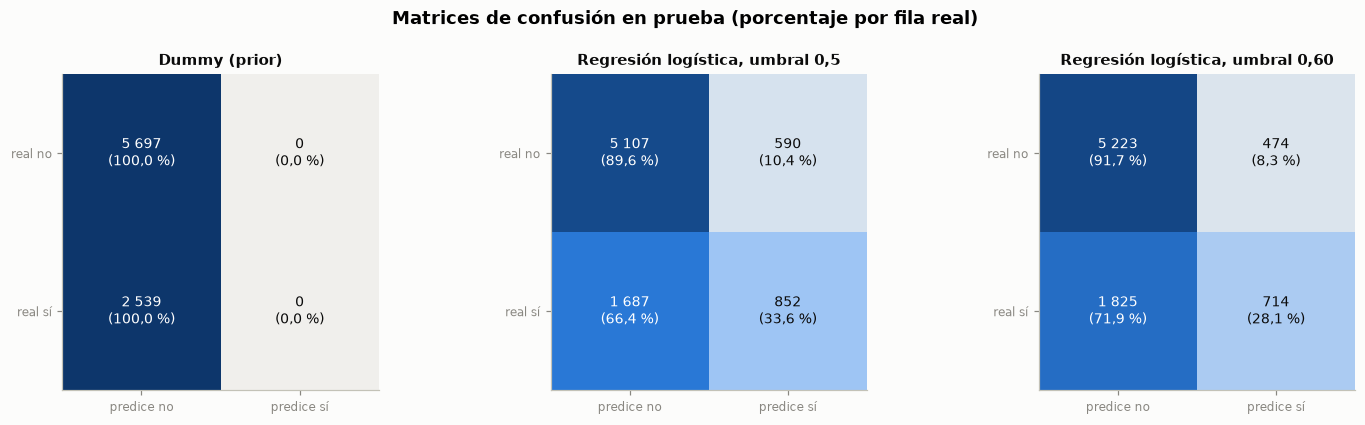

**Lectura.** Con umbral 0,5 el modelo detecta 852 de los 2 539 clientes que suscriben y marca 590 falsos positivos: de sus 1 442 llamadas recomendadas, el 59,1 % terminaría en suscripción. Con el umbral de 0,60 detecta 714 (28,1 %) a cambio de 474 falsos positivos: de 1 188 llamadas, el 60,1 % terminaría en suscripción. Si se llamara al azar, la tasa de éxito sería del 30,8 %. El Dummy no recomienda ninguna llamada.

**Implicación predictiva.** Con umbral 0,5 la lista es corta y más precisa que llamar al azar (1,9 veces la tasa base), pero deja por fuera a la mayoría de quienes suscriben. Con el umbral elegido se llamaría al 14,4 % de los clientes y se capturaría el 28,1 % de las suscripciones, con una tasa de éxito 1,9 veces la de llamar al azar.

**Acción recomendada.** Usar la matriz de confusión para estimar el costo y el beneficio de la campaña cuando el banco aporte los valores económicos, y elegir el punto de operación según la capacidad de llamadas, no con un umbral fijo.

In [38]:
fig, axs = plt.subplots(1, 3, figsize=(13.5, 3.9))
for ax, (nombre, (_, pred)) in zip(axs, modelos_eval.items()):
    cm = confusion_matrix(yv, pred, labels=[0, 1])
    filas_pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(filas_pct, cmap=CMAP_SEQ, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{num(cm[i, j])}\n({pct(filas_pct[i, j])})", ha="center", va="center", fontsize=9,
                    color="white" if filas_pct[i, j] > 0.6 else TINTA)
    ax.set_xticks([0, 1], ["predice no", "predice sí"])
    ax.set_yticks([0, 1], ["real no", "real sí"])
    ax.grid(False)
    ax.set_title(nombre, fontsize=9.5)
fig.suptitle("Matrices de confusión en prueba (porcentaje por fila real)")
plt.tight_layout()
plt.show()

cm_u = confusion_matrix(yv, pred_u, labels=[0, 1])
cm_5 = confusion_matrix(yv, pred_05, labels=[0, 1])
llamadas_u, llamadas_5 = cm_u[:, 1].sum(), cm_5[:, 1].sum()
interpretar(
    f"Con umbral 0,5 el modelo detecta {num(cm_5[1, 1])} de los {num(cm_5[1].sum())} clientes que suscriben y marca "
    f"{num(cm_5[0, 1])} falsos positivos: de sus {num(llamadas_5)} llamadas recomendadas, el "
    f"{pct(cm_5[1, 1] / llamadas_5 if llamadas_5 else 0)} terminaría en suscripción. Con el umbral de {num(umbral, 2)} "
    f"detecta {num(cm_u[1, 1])} ({pct(cm_u[1, 1] / cm_u[1].sum())}) a cambio de {num(cm_u[0, 1])} falsos positivos: de "
    f"{num(llamadas_u)} llamadas, el {pct(cm_u[1, 1] / llamadas_u if llamadas_u else 0)} terminaría en suscripción. Si se "
    f"llamara al azar, la tasa de éxito sería del {pct(prev_te)}. El Dummy no recomienda ninguna llamada.",
    (f"Con umbral 0,5 la lista es corta y más precisa que llamar al azar ("
     f"{num((cm_5[1, 1] / llamadas_5) / prev_te if llamadas_5 else 0, 1)} veces la tasa base)"
     + (", pero deja por fuera a la mayoría de quienes suscriben. " if cm_5[1, 1] / cm_5[1].sum() < 0.5 else ". ")
     if llamadas_5 else "")
    + (f"Con el umbral elegido, en cambio, se llamaría al {pct(llamadas_u / len(yv))} de los clientes: el modelo pierde "
       "selectividad porque el umbral se aprendió con una prevalencia mucho menor."
       if llamadas_u / len(yv) > 0.6 else
       f"Con el umbral elegido se llamaría al {pct(llamadas_u / len(yv))} de los clientes y se capturaría el "
       f"{pct(cm_u[1, 1] / cm_u[1].sum())} de las suscripciones, con una tasa de éxito "
       f"{num((cm_u[1, 1] / llamadas_u) / prev_te if llamadas_u else 0, 1)} veces la de llamar al azar."),
    "Usar la matriz de confusión para estimar el costo y el beneficio de la campaña cuando el banco aporte los "
    "valores económicos, y elegir el punto de operación según la capacidad de llamadas, no con un umbral fijo.")

## 4.6 Curvas ROC y precisión-recall

Con clases desbalanceadas, la curva precisión-recall es más informativa que la ROC, porque su línea base es la prevalencia y no 0,5 (Saito y Rehmsmeier, 2015).

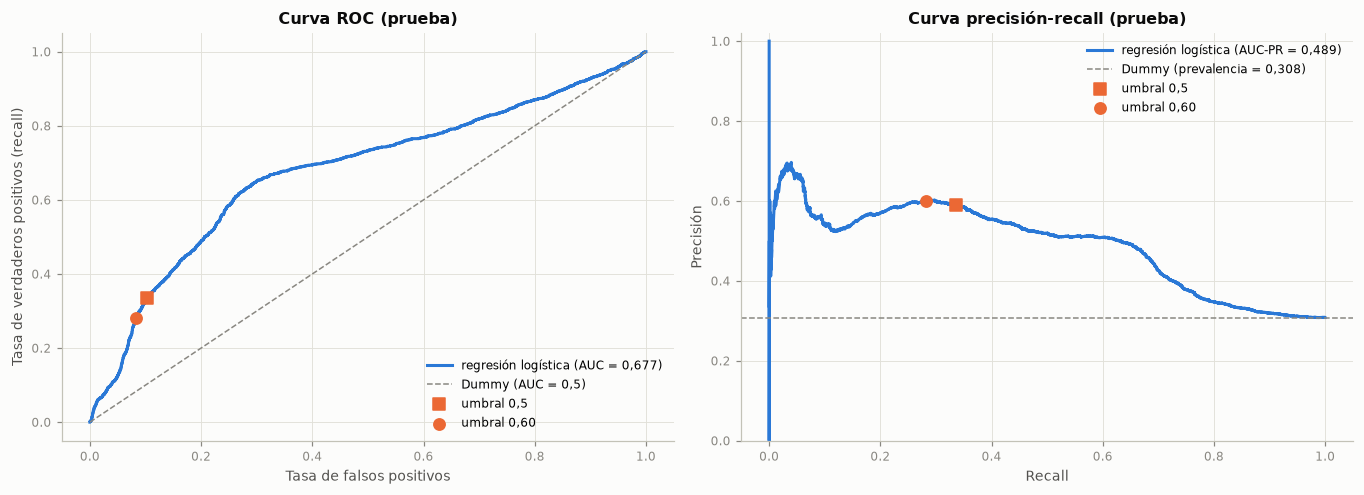

**Lectura.** La curva ROC queda por encima de la diagonal (AUC = 0,677). En la curva precisión-recall, con un recall de 20 % la precisión es 0,57, con 50 % es 0,52 y para recall altos se acerca a la prevalencia (0,308). En el 5 % de clientes con mayor probabilidad suscribe el 56,1 % y el 46,4 % tuvo éxito en una campaña anterior, frente al 14,6 % en toda la prueba.

**Implicación predictiva.** El modelo identifica mejor a un grupo reducido de clientes muy probables, definido sobre todo por el historial con el banco, que es la señal que mejor se transfiere de un periodo a otro; para el resto, los perfiles de quienes suscriben y quienes no se parecen mucho.

**Acción recomendada.** Si la capacidad de llamadas es limitada, priorizar por probabilidad y elegir el punto de la curva PR que corresponda a esa capacidad; no forzar recall altos con este modelo.

In [39]:
fpr, tpr, _ = roc_curve(yv, prob_te)
prec_c, rec_c, _ = precision_recall_curve(yv, prob_te)
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.6))
axs[0].plot(fpr, tpr, color=AZUL, label=f"regresión logística (AUC = {num(P[nombre_u]['AUC'], 3)})")
axs[0].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="Dummy (AUC = 0,5)")
axs[1].plot(rec_c, prec_c, color=AZUL, label=f"regresión logística (AUC-PR = {num(P[nombre_u]['AUC-PR'], 3)})")
axs[1].axhline(prev_te, color=GRIS, ls="--", lw=1, label=f"Dummy (prevalencia = {num(prev_te, 3)})")
for pred, etiqueta, marca in [(pred_05, "umbral 0,5", "s"), (pred_u, f"umbral {num(umbral, 2)}", "o")]:
    cm_ = confusion_matrix(yv, pred, labels=[0, 1])
    tpr_p, fpr_p = cm_[1, 1] / cm_[1].sum(), cm_[0, 1] / cm_[0].sum()
    prec_p = cm_[1, 1] / cm_[:, 1].sum() if cm_[:, 1].sum() else 0
    axs[0].scatter(fpr_p, tpr_p, color=NARANJA, marker=marca, s=55, zorder=3, label=etiqueta)
    axs[1].scatter(tpr_p, prec_p, color=NARANJA, marker=marca, s=55, zorder=3, label=etiqueta)
axs[0].set_xlabel("Tasa de falsos positivos")
axs[0].set_ylabel("Tasa de verdaderos positivos (recall)")
axs[0].set_title("Curva ROC (prueba)")
axs[1].set_xlabel("Recall")
axs[1].set_ylabel("Precisión")
axs[1].set_title("Curva precisión-recall (prueba)")
axs[1].set_ylim(0, 1.02)
for a in axs:
    a.legend(loc="lower right" if a is axs[0] else "upper right")
plt.tight_layout()
plt.show()


def precision_en_recall(r):
    i = np.flatnonzero(rec_c >= r)[-1]   # recall está en orden decreciente
    return prec_c[i]


top5 = prob_te >= np.quantile(prob_te, 0.95)
share_success_top = (X_te["poutcome"].to_numpy()[top5] == "success").mean()
share_success_te = (X_te["poutcome"] == "success").mean()
prev_top5 = yv[top5].mean()
interpretar(
    f"La curva ROC queda por encima de la diagonal (AUC = {num(P[nombre_u]['AUC'], 3)}). En la curva "
    f"precisión-recall, con un recall de 20 % la precisión es {num(precision_en_recall(0.2), 2)}, con 50 % es "
    f"{num(precision_en_recall(0.5), 2)} y para recall altos se acerca a la prevalencia ({num(prev_te, 3)}). En el "
    f"5 % de clientes con mayor probabilidad suscribe el {pct(prev_top5)} y el {pct(share_success_top)} tuvo éxito en "
    f"una campaña anterior, frente al {pct(share_success_te)} en toda la prueba.",
    "El modelo identifica mejor a un grupo reducido de clientes muy probables, definido sobre todo por el historial "
    "con el banco, que es la señal que mejor se transfiere de un periodo a otro; para el resto, los perfiles de "
    "quienes suscriben y quienes no se parecen mucho.",
    "Si la capacidad de llamadas es limitada, priorizar por probabilidad y elegir el punto de la curva PR que "
    "corresponda a esa capacidad; no forzar recall altos con este modelo.")

## 4.7 Calibración

La calibración compara la probabilidad predicha con la frecuencia observada de suscripción en diez grupos de igual tamaño (cuantiles de la probabilidad). El puntaje de Brier mide el error cuadrático de las probabilidades; el *Brier skill score* (BSS) lo compara con el del Dummy, que asigna a todos la prevalencia de entrenamiento (0 = igual que el Dummy, 1 = perfecto).

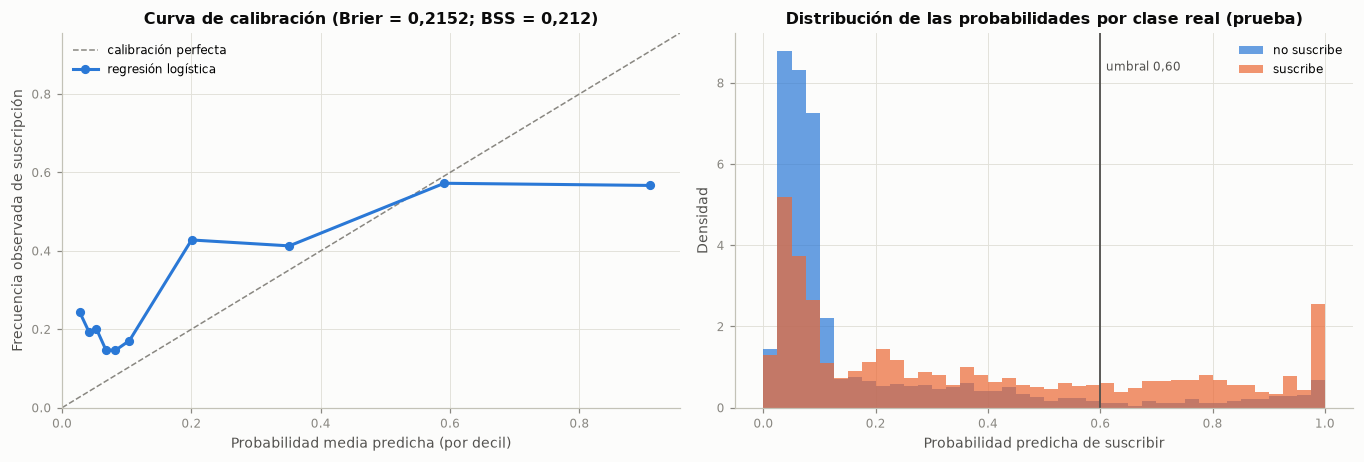

**Lectura.** La probabilidad media predicha en prueba es 0,243 frente a una tasa observada de 0,308 (diferencia de -0,066). En 8 de los 10 deciles la frecuencia observada supera a la predicha; la desviación absoluta media es de 0,138 y la máxima de 0,343. El Brier del modelo es 0,2152 frente a 0,2730 del Dummy (BSS = 0,212).

**Implicación predictiva.** El modelo subestima la probabilidad de suscribir en prueba: aprendió con una tasa base menor y no puede anticipar el aumento de la prevalencia. Por eso sus probabilidades sirven para ordenar clientes, pero no se pueden leer directamente como frecuencias esperadas en un periodo nuevo sin recalibrar.

**Acción recomendada.** Mantener la regresión logística sin reponderar clases y, en el siguiente entregable, evaluar una recalibración del intercepto con los datos más recientes antes de cualquier uso operativo.

In [40]:
frac_pos, prob_media = calibration_curve(yv, prob_te, n_bins=10, strategy="quantile")
bss = 1 - P[nombre_u]["Brier"] / P["Dummy (prior)"]["Brier"]
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.3))
lim = max(prob_media.max(), frac_pos.max()) * 1.05
axs[0].plot([0, lim], [0, lim], color=GRIS, ls="--", lw=1, label="calibración perfecta")
axs[0].plot(prob_media, frac_pos, color=AZUL, marker="o", ms=5, label="regresión logística")
axs[0].set_xlabel("Probabilidad media predicha (por decil)")
axs[0].set_ylabel("Frecuencia observada de suscripción")
axs[0].set_title(f"Curva de calibración (Brier = {num(P[nombre_u]['Brier'], 4)}; BSS = {num(bss, 3)})")
axs[0].legend(loc="upper left")
axs[0].set_xlim(0, lim)
axs[0].set_ylim(0, lim)
bins_h = np.linspace(0, 1, 41)
for clase in (0, 1):
    axs[1].hist(prob_te[yv == clase], bins=bins_h, color=COLOR_Y[clase], alpha=0.7, label=ETIQUETA_Y[clase],
                density=True)
axs[1].axvline(umbral, color=TINTA_2, lw=1.2)
axs[1].text(umbral + 0.01, axs[1].get_ylim()[1] * 0.9, f"umbral {num(umbral, 2)}", fontsize=8, color=TINTA_2)
axs[1].set_xlabel("Probabilidad predicha de suscribir")
axs[1].set_ylabel("Densidad")
axs[1].set_title("Distribución de las probabilidades por clase real (prueba)")
axs[1].legend()
plt.tight_layout()
plt.show()

err_cal = np.abs(frac_pos - prob_media)
sesgo_cal = prob_te.mean() - prev_te
deciles_bajo = int((frac_pos > prob_media).sum())
interpretar(
    f"La probabilidad media predicha en prueba es {num(prob_te.mean(), 3)} frente a una tasa observada de "
    f"{num(prev_te, 3)} (diferencia de {num(sesgo_cal, 3)}). En {deciles_bajo} de los {len(frac_pos)} deciles la "
    f"frecuencia observada supera a la predicha; la desviación absoluta media es de {num(err_cal.mean(), 3)} y la "
    f"máxima de {num(err_cal.max(), 3)}. El Brier del modelo es {num(P[nombre_u]['Brier'], 4)} frente a "
    f"{num(P['Dummy (prior)']['Brier'], 4)} del Dummy (BSS = {num(bss, 3)}).",
    ("El modelo subestima la probabilidad de suscribir en prueba: aprendió con una tasa base menor y no puede "
     "anticipar el aumento de la prevalencia. " if sesgo_cal < -0.02 else
     ("El modelo sobrestima la probabilidad de suscribir en prueba. " if sesgo_cal > 0.02 else
      "La probabilidad media predicha coincide con la tasa observada en prueba. "))
    + "Por eso sus probabilidades sirven para ordenar clientes, pero no se pueden leer directamente como "
    "frecuencias esperadas en un periodo nuevo sin recalibrar.",
    "Mantener la regresión logística sin reponderar clases y, en el siguiente entregable, evaluar una recalibración "
    "del intercepto con los datos más recientes antes de cualquier uso operativo.")

## 4.8 Curva de aprendizaje

Con datos temporales, la curva de aprendizaje se construye con los tres últimos pliegues de la validación temporal (los dos primeros tienen poca historia): para cada tamaño *n*, el modelo se ajusta con los *n* registros **más recientes** anteriores al bloque de validación (respetando la separación) y se evalúa en ese bloque. Así se mide si agregar historia más antigua mejora la predicción del periodo siguiente.

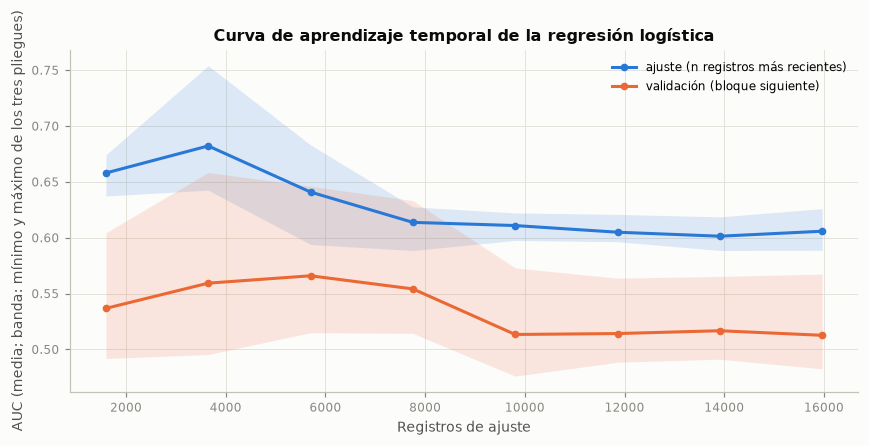

**Lectura.** Con los 1 596 registros más recientes el AUC de validación promedio es 0,537 y con 15 963 es 0,513; el máximo (0,566) se alcanza con 5 701 registros. La brecha entre ajuste y validación pasa de 0,121 a 0,093.

**Implicación predictiva.** Agregar historia más antigua mejora poco la predicción del bloque siguiente; incluso puede empeorarla, porque los periodos antiguos describen un contexto distinto. La brecha que persiste con todos los registros no es sobreajuste por tamaño de muestra sino deriva: el modelo describe bien el periodo con el que se ajusta y peor el siguiente.

**Acción recomendada.** El tamaño de muestra es suficiente; las mejoras deben venir de adaptar el modelo al cambio de periodo y de modelos más flexibles en los siguientes entregables, no de acumular más historia.

In [41]:
pliegues_lc = list(tss.split(X_tr))[-3:]
n_max = min(len(i_ent) for i_ent, _ in pliegues_lc)
tamanos = np.unique((np.linspace(0.1, 1.0, 8) * n_max).astype(int))
auc_ent = np.zeros((len(tamanos), len(pliegues_lc)))
auc_val = np.zeros_like(auc_ent)
for a, n_ in enumerate(tamanos):
    for b, (i_ent, i_val) in enumerate(pliegues_lc):
        sub = i_ent[-n_:]
        m_ = construir_modelo(C=C_opt).fit(X_tr.iloc[sub], y_tr.iloc[sub])
        auc_ent[a, b] = roc_auc_score(y_tr.iloc[sub], m_.predict_proba(X_tr.iloc[sub])[:, 1])
        auc_val[a, b] = roc_auc_score(y_tr.iloc[i_val], m_.predict_proba(X_tr.iloc[i_val])[:, 1])

fig, ax = plt.subplots(figsize=(8, 4))
for datos, col, etiqueta in [(auc_ent, AZUL, "ajuste (n registros más recientes)"), (auc_val, NARANJA, "validación (bloque siguiente)")]:
    ax.plot(tamanos, datos.mean(axis=1), color=col, marker="o", ms=4, label=etiqueta)
    ax.fill_between(tamanos, datos.min(axis=1), datos.max(axis=1), color=col, alpha=0.15, linewidth=0)
ax.set_xlabel("Registros de ajuste")
ax.set_ylabel("AUC (media; banda: mínimo y máximo de los tres pliegues)")
ax.set_title("Curva de aprendizaje temporal de la regresión logística")
ax.legend()
plt.tight_layout()
plt.show()

v_ini, v_fin = auc_val.mean(axis=1)[0], auc_val.mean(axis=1)[-1]
brecha_ini = auc_ent.mean(axis=1)[0] - v_ini
brecha_fin = auc_ent.mean(axis=1)[-1] - v_fin
interpretar(
    f"Con los {num(tamanos[0])} registros más recientes el AUC de validación promedio es {num(v_ini, 3)} y con "
    f"{num(tamanos[-1])} es {num(v_fin, 3)}; el máximo ({num(auc_val.mean(axis=1).max(), 3)}) se alcanza con "
    f"{num(tamanos[int(np.argmax(auc_val.mean(axis=1)))])} registros. La brecha entre ajuste y validación pasa de "
    f"{num(brecha_ini, 3)} a {num(brecha_fin, 3)}.",
    ("Agregar historia más antigua mejora poco la predicción del bloque siguiente"
     if v_fin - v_ini < 0.02 else "Agregar historia más antigua mejora la predicción del bloque siguiente")
    + ("; incluso puede empeorarla, porque los periodos antiguos describen un contexto distinto. "
       if v_fin < auc_val.mean(axis=1).max() - 0.01 else ". ")
    + "La brecha que persiste con todos los registros no es sobreajuste por tamaño de muestra sino deriva: el "
    "modelo describe bien el periodo con el que se ajusta y peor el siguiente.",
    "El tamaño de muestra es suficiente; las mejoras deben venir de adaptar el modelo al cambio de periodo y de "
    "modelos más flexibles en los siguientes entregables, no de acumular más historia.")

## 4.9 Interpretación de los coeficientes

Los coeficientes son log-odds. Para las numéricas, el *odds ratio* (OR) corresponde al cambio de una desviación estándar en la variable transformada (después de `log1p` en `campaign` y `previous`); para las categóricas, compara cada categoría con la de referencia (la primera en orden alfabético). Un OR mayor que 1 aumenta las chances de suscribir y uno menor que 1 las reduce, **manteniendo constantes las demás variables**. Son asociaciones aprendidas con el periodo de entrenamiento, no efectos causales.

Intercepto: -3,277 · columnas: 49 · C = 100


,Coeficiente,Odds ratio,Grupo
"month = infrecuente: dec, oct (ref. apr)","2,751","15,653",calendario
month = mar (ref. apr),"1,091","2,976",calendario
month = jun (ref. apr),"-0,966","0,381",calendario
education = infrecuente: illiterate (ref. basic.4y),"0,906","2,475",atributos del cliente
poutcome = nonexistent (ref. failure),"0,733","2,081",historial y campaña
month = may (ref. apr),"-0,687","0,503",calendario
poutcome = success (ref. failure),"-0,639","0,528",historial y campaña
job = retired (ref. admin.),"0,603","1,828",atributos del cliente
month = jul (ref. apr),"-0,557","0,573",calendario
job = student (ref. admin.),"0,520","1,682",atributos del cliente


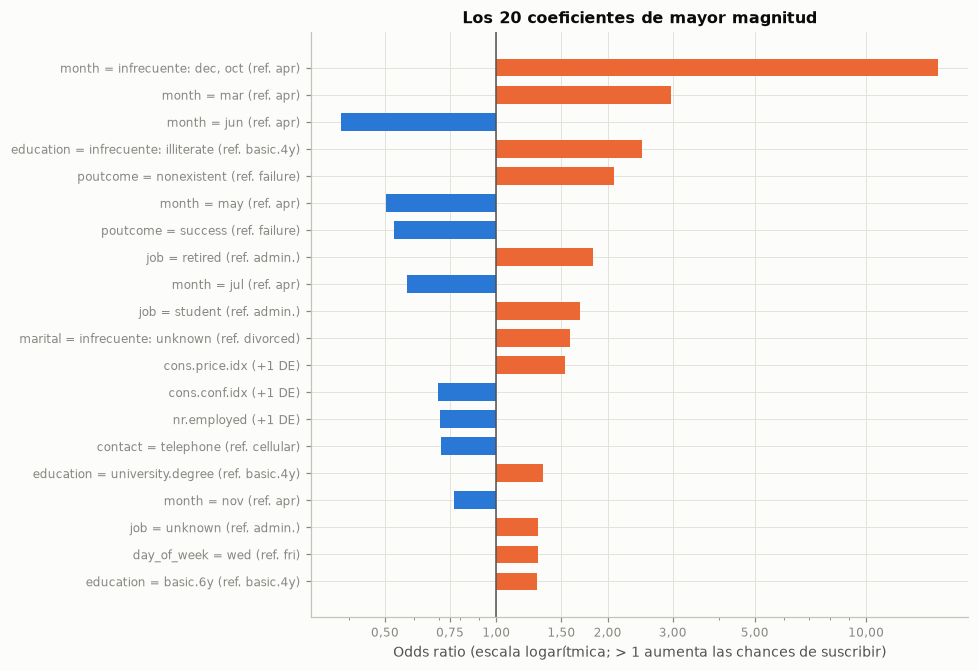

**Lectura.** Los mayores aumentos de las chances corresponden a `month = infrecuente: dec, oct (ref. apr)` (OR = 15,65); `month = mar (ref. apr)` (OR = 2,98); `education = infrecuente: illiterate (ref. basic.4y)` (OR = 2,48). Las mayores reducciones, a `month = jun (ref. apr)` (OR = 0,38); `month = may (ref. apr)` (OR = 0,50); `poutcome = success (ref. failure)` (OR = 0,53). Entre los 10 coeficientes más grandes hay 5 de calendario, 3 de atributos del cliente y 2 de historial y campaña.

**Implicación predictiva.** Los coeficientes de calendario y macroeconómicos describen el periodo de entrenamiento (sobre todo 2008): mezclan el efecto estacional con la tasa base de cada mes y no tienen por qué repetirse en periodos posteriores, lo que ayuda a explicar la caída de desempeño fuera del periodo de ajuste. La categoría infrecuente de `month` (dec y oct, con 77 registros en entrenamiento) tiene un OR de 15,65 estimado con muy pocos casos, y en prueba también recibe a los meses no vistos en entrenamiento (sep), así que ese efecto se extrapola a meses que el modelo nunca observó. Algunos signos son contraintuitivos, como `poutcome = success` con OR de 0,53 frente a `failure`: `poutcome`, `pdays` y `previous` están ligadas por construcción (sección 3.3.2) y, con una regularización débil (C = 100), el efecto del historial se reparte entre ellas. Además, `housing = unknown` y `loan = unknown` son la misma información (sección 3.3.3), así que la penalización reparte su efecto entre ambas.

**Acción recomendada.** Usar los odds ratios para explicar el modelo, no para decidir intervenciones; y en el siguiente entregable evaluar si conviene reemplazar las variables de calendario por otras que se transfieran mejor entre periodos.

In [42]:
pre_f = modelo_final.named_steps["pre"]
lr_f = modelo_final.named_steps["lr"]
cod_f = pre_f.named_transformers_["cat"]
referencias = {c: cod_f.categories_[i][cod_f.drop_idx_[i]] for i, c in enumerate(VARS_CAT)}
infrec_f = {c: list(v) for c, v in zip(VARS_CAT, cod_f.infrequent_categories_) if v is not None}


def nombre_legible(n):
    bloque, var = n.split("__", 1)
    if bloque == "num":
        return f"{var} (+1 DE)"
    if bloque == "log":
        return f"log1p({var}) (+1 DE)"
    if bloque == "pdays":
        return "pdays = 999 (sin registro de días)" if var.startswith("missingindicator") else "pdays (+1 DE)"
    for c in sorted(VARS_CAT, key=len, reverse=True):
        if var.startswith(c + "_"):
            cat = var[len(c) + 1:]
            if cat == "infrequent_sklearn":
                cat = "infrecuente: " + ", ".join(infrec_f.get(c, []))
            return f"{c} = {cat} (ref. {referencias[c]})"
    return var


def grupo_coef(nombre):
    if nombre.startswith(("month", "day_of_week")):
        return "calendario"
    if nombre.startswith(("cons.", "nr.employed")):
        return "macroeconómicas"
    if nombre.startswith(("poutcome", "pdays", "log1p(previous)", "log1p(campaign)")):
        return "historial y campaña"
    if nombre.startswith("contact"):
        return "canal"
    return "atributos del cliente"


coefs = pd.DataFrame({"Coeficiente": lr_f.coef_[0]},
                     index=[nombre_legible(n) for n in pre_f.get_feature_names_out()])
coefs["Odds ratio"] = np.exp(coefs["Coeficiente"])
coefs["Grupo"] = [grupo_coef(i) for i in coefs.index]
coefs = coefs.reindex(coefs["Coeficiente"].abs().sort_values(ascending=False).index)
print(f"Intercepto: {num(lr_f.intercept_[0], 3)} · columnas: {len(coefs)} · C = {num_c(C_opt)}")
tabla(coefs.head(20), dec=3)

top = coefs.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6.2))
ax.barh(top.index, top["Odds ratio"] - 1, left=1, color=[NARANJA if v > 1 else AZUL for v in top["Odds ratio"]],
        height=0.65)
ax.set_xscale("log")
marcas = [m for m in (0.1, 0.2, 0.3, 0.5, 0.75, 1, 1.5, 2, 3, 5, 10)
          if top["Odds ratio"].min() * 0.9 <= m <= top["Odds ratio"].max() * 1.1]
ax.set_xticks(marcas, [num(m, 2) for m in marcas])
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.axvline(1, color=TINTA_2, lw=1)
ax.set_xlabel("Odds ratio (escala logarítmica; > 1 aumenta las chances de suscribir)")
ax.set_title("Los 20 coeficientes de mayor magnitud")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

pos_ = coefs[coefs["Coeficiente"] > 0].head(3)
fila_inf_mes = [i for i in coefs.index if i.startswith("month = infrecuente")]
meses_no_vistos_te = [m for m in ORDEN_MESES if m in set(X_te["month"]) and m not in set(X_tr["month"])]
or_success = coefs.loc[[i for i in coefs.index if i.startswith("poutcome = success")], "Odds ratio"]
neg_ = coefs[coefs["Coeficiente"] < 0].head(3)
grupos_top = coefs.head(10)["Grupo"].value_counts()
interpretar(
    "Los mayores aumentos de las chances corresponden a "
    + "; ".join(f"`{i}` (OR = {num(r['Odds ratio'], 2)})" for i, r in pos_.iterrows())
    + ". Las mayores reducciones, a "
    + "; ".join(f"`{i}` (OR = {num(r['Odds ratio'], 2)})" for i, r in neg_.iterrows())
    + ". Entre los 10 coeficientes más grandes hay "
    + enumerar([f"{v} de {k}" for k, v in grupos_top.items()], codigo=False) + ".",
    "Los coeficientes de calendario y macroeconómicos describen el periodo de entrenamiento (sobre todo 2008): "
    "mezclan el efecto estacional con la tasa base de cada mes y no tienen por qué repetirse en periodos "
    "posteriores, lo que ayuda a explicar la caída de desempeño fuera del periodo de ajuste. "
    + (f"La categoría infrecuente de `month` ({enumerar(infrec_f.get('month', []), codigo=False)}, con "
       f"{num(int(X_tr['month'].isin(infrec_f.get('month', [])).sum()))} registros en entrenamiento) tiene un OR de "
       f"{num(coefs.loc[fila_inf_mes[0], 'Odds ratio'], 2)} estimado con muy pocos casos"
       + (f", y en prueba también recibe a los meses no vistos en entrenamiento ({enumerar(meses_no_vistos_te, codigo=False)}), "
          "así que ese efecto se extrapola a meses que el modelo nunca observó. " if meses_no_vistos_te else ". ")
       if fila_inf_mes else "")
    + (f"Algunos signos son contraintuitivos, como `poutcome = success` con OR de {num(or_success.iloc[0], 2)} frente "
       "a `failure`: `poutcome`, `pdays` y `previous` están ligadas por construcción (sección 3.3.2) y, con una "
       f"regularización débil (C = {num_c(C_opt)}), el efecto del historial se reparte entre ellas. "
       if len(or_success) and or_success.iloc[0] < 1 else "")
    + "Además, `housing = unknown` y `loan = unknown` son la misma información (sección 3.3.3), así que la "
    "penalización reparte su efecto entre ambas.",
    "Usar los odds ratios para explicar el modelo, no para decidir intervenciones; y en el siguiente entregable "
    "evaluar si conviene reemplazar las variables de calendario por otras que se transfieran mejor entre periodos.")

## 4.10 Diagnóstico temporal: contraste con la validación aleatoria, desempeño por año y residuos

El enunciado pide comprobar que la validación respete la estructura de los datos y revisar la dependencia de los residuos. Se compara la validación temporal del modelo final con la que habría dado una validación estratificada aleatoria sobre el mismo entrenamiento (contraste), se mide el desempeño en prueba por año y se calcula la autocorrelación de los residuos de Pearson en prueba, en el orden temporal de las filas.

,AUC,AUC-PR
Validación temporal en entrenamiento (esquema usado),"0,542","0,097"
Validación aleatoria estratificada en entrenamiento (contraste),"0,668","0,202"
Prueba cronológica,"0,677","0,489"


,Registros,Prevalencia,Probabilidad media predicha,AUC,AUC-PR
Año (prueba),,,,,
2009,6 178,"0,237","0,136","0,593","0,377"
2010,2 058,"0,521","0,564","0,585","0,577"


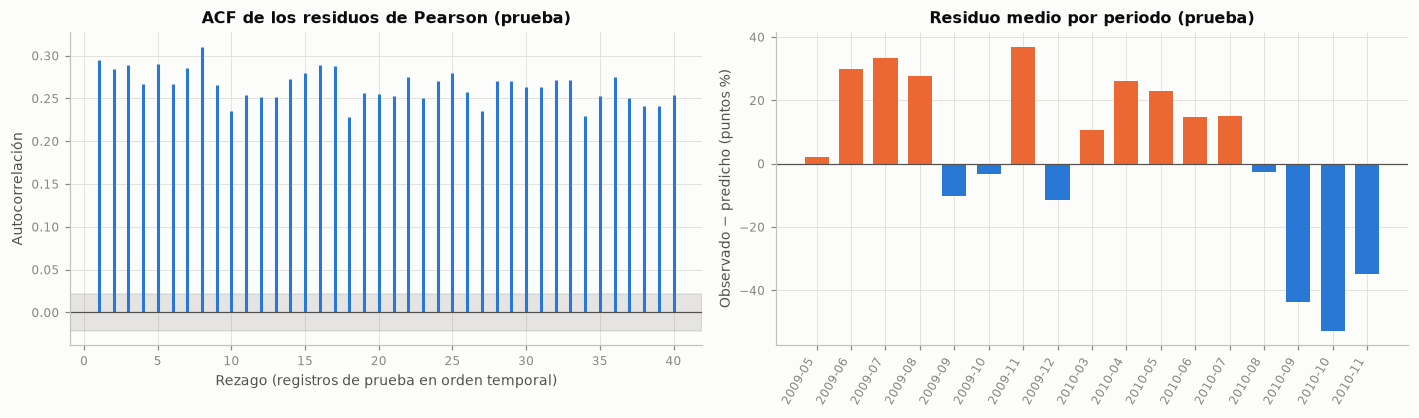

Ljung-Box: Q(10) = 6 442,9 (p < 0,001); Q(40) = 23 270,4 (p < 0,001)


**Lectura.** Si se hubiera validado de forma aleatoria, el AUC estimado en entrenamiento sería de 0,668, frente a 0,542 de la validación temporal; en la prueba cronológica el AUC es 0,677. Por año, en prueba: 2009: 6 178 registros, prevalencia 0,237, probabilidad media predicha 0,136 y AUC 0,593; 2010: 2 058 registros, prevalencia 0,521, probabilidad media predicha 0,564 y AUC 0,585. El residuo medio supera los 5 puntos porcentuales en 9 de los 17 periodos de prueba; en los meses que el modelo trata como infrecuentes o no vio en entrenamiento (sep, oct y dec; 1 392 registros de prueba) el residuo medio es de -21,7 puntos, frente a 12,3 en los demás. Los residuos tienen 40 de 40 rezagos fuera de la banda del 95 % y la prueba de Ljung-Box rechaza la ausencia de autocorrelación hasta el rezago 40 (p < 0,001).

**Implicación predictiva.** La validación aleatoria habría sobrestimado la capacidad del modelo para el periodo siguiente, lo que confirma que respetar el orden temporal era necesario. El AUC global de prueba (0,677) es mayor que el de cada año por separado (0,593 y 0,585): una parte viene de ordenar bien entre periodos, porque el modelo asigna probabilidades más altas al año con mayor tasa de suscripción, extrapolando el contexto a partir de las macro y del mes, y no solo de distinguir clientes dentro de un mismo periodo. Aun así, el AUC de prueba supera al de la validación temporal, dominada por bloques de 2008 con muy poca señal: el desempeño depende del periodo evaluado y una sola cifra no lo resume. La sobrestimación en los meses infrecuentes o no vistos proviene del coeficiente de la categoría infrecuente de `month` (sección 4.9), estimado con muy pocos casos de 2008 y extrapolado a otros meses. Los residuos medios por periodo y su autocorrelación muestran que el error cambia de un periodo a otro: hay información temporal, como la tasa base de cada periodo, que el modelo no captura.

**Acción recomendada.** Mantener la validación temporal como esquema principal y, en el siguiente entregable, estudiar cómo adaptar la tasa base (por ejemplo, reajustando el intercepto o el umbral con los datos más recientes) sin usar información del futuro.

In [43]:
cv_contraste = cross_validate(construir_modelo(C=C_opt), X_tr, y_tr, cv=skf, scoring=["roc_auc", "average_precision"])
contraste = pd.DataFrame({
    "AUC": [grid.best_score_, cv_contraste["test_roc_auc"].mean(), P[nombre_u]["AUC"]],
    "AUC-PR": [res_grid.loc[i_opt, "mean_test_auc_pr"], cv_contraste["test_average_precision"].mean(),
               P[nombre_u]["AUC-PR"]]},
    index=["Validación temporal en entrenamiento (esquema usado)",
           "Validación aleatoria estratificada en entrenamiento (contraste)", "Prueba cronológica"])
tabla(contraste, dec=3)

mask_anio = {a: (anio_te == a).to_numpy() for a in sorted(anio_te.unique())}
por_anio_te = pd.DataFrame({
    a: {"Registros": int(m.sum()), "Prevalencia": yv[m].mean(), "Probabilidad media predicha": prob_te[m].mean(),
        "AUC": roc_auc_score(yv[m], prob_te[m]), "AUC-PR": average_precision_score(yv[m], prob_te[m])}
    for a, m in mask_anio.items()}).T.rename_axis("Año (prueba)")
por_anio_te["Registros"] = por_anio_te["Registros"].astype(int)
tabla(por_anio_te, dec=3)

resid = (yv - prob_te) / np.sqrt(prob_te * (1 - prob_te))   # X_te ya está en orden temporal
acf_res = acf(resid, nlags=40, fft=True)
lb = acorr_ljungbox(resid, lags=[10, 40])
banda = 1.96 / np.sqrt(len(resid))
res_periodo = pd.Series(yv - prob_te).groupby(periodo_te.to_numpy()).mean()

fig, axs = plt.subplots(1, 2, figsize=(13, 3.9))
axs[0].vlines(range(1, 41), 0, acf_res[1:], color=AZUL, lw=2)
axs[0].axhspan(-banda, banda, color=GRIS, alpha=0.2)
axs[0].axhline(0, color=TINTA_2, lw=0.8)
axs[0].set_xlabel("Rezago (registros de prueba en orden temporal)")
axs[0].set_ylabel("Autocorrelación")
axs[0].set_title("ACF de los residuos de Pearson (prueba)")
xp = np.arange(len(res_periodo))
axs[1].bar(xp, 100 * res_periodo.values, color=[NARANJA if v > 0 else AZUL for v in res_periodo.values], width=0.7)
axs[1].axhline(0, color=TINTA_2, lw=0.8)
axs[1].set_xticks(xp, res_periodo.index, rotation=60, ha="right")
axs[1].set_ylabel("Observado − predicho (puntos %)")
axs[1].set_title("Residuo medio por periodo (prueba)")
plt.tight_layout()
plt.show()
print(f"Ljung-Box: Q(10) = {num(lb['lb_stat'].iloc[0], 1)} ({p_txt(lb['lb_pvalue'].iloc[0])}); "
      f"Q(40) = {num(lb['lb_stat'].iloc[1], 1)} ({p_txt(lb['lb_pvalue'].iloc[1])})")

auc_cv_alea = cv_contraste["test_roc_auc"].mean()
meses_extrap = [m for m in ORDEN_MESES if m in set(infrec_f.get("month", [])) | set(meses_no_vistos_te)]
m_ext = X_te["month"].isin(meses_extrap).to_numpy()
res_ext = (yv - prob_te)[m_ext].mean() if m_ext.any() else np.nan
res_resto = (yv - prob_te)[~m_ext].mean()
sig_acf = int((np.abs(acf_res[1:]) > banda).sum())
periodos_sub = int((res_periodo > 0.05).sum())
interpretar(
    f"Si se hubiera validado de forma aleatoria, el AUC estimado en entrenamiento sería de {num(auc_cv_alea, 3)}, "
    f"frente a {num(grid.best_score_, 3)} de la validación temporal; en la prueba cronológica el AUC es "
    f"{num(P[nombre_u]['AUC'], 3)}. Por año, en prueba: "
    + "; ".join(f"{a}: {num(int(r['Registros']))} registros, prevalencia {num(r['Prevalencia'], 3)}, probabilidad media "
                f"predicha {num(r['Probabilidad media predicha'], 3)} y AUC {num(r['AUC'], 3)}"
                for a, r in por_anio_te.iterrows())
    + f". El residuo medio supera los 5 puntos porcentuales en {periodos_sub} de los {len(res_periodo)} periodos de "
    "prueba"
    + (f"; en los meses que el modelo trata como infrecuentes o no vio en entrenamiento ({enumerar(meses_extrap, codigo=False)}; "
       f"{num(int(m_ext.sum()))} registros de prueba) el residuo medio es de {num(100 * res_ext, 1)} puntos, frente a "
       f"{num(100 * res_resto, 1)} en los demás" if m_ext.any() else "")
    + f". Los residuos tienen {sig_acf} de 40 rezagos fuera de la banda del 95 % y la prueba de Ljung-Box "
    f"{'rechaza' if lb['lb_pvalue'].iloc[1] < 0.05 else 'no rechaza'} la ausencia de autocorrelación hasta el rezago 40 "
    f"({p_txt(lb['lb_pvalue'].iloc[1])}).",
    ("La validación aleatoria habría sobrestimado la capacidad del modelo para el periodo siguiente, lo que confirma "
     "que respetar el orden temporal era necesario. " if auc_cv_alea > grid.best_score_ + 0.05 else "")
    + (f"El AUC global de prueba ({num(P[nombre_u]['AUC'], 3)}) es mayor que el de cada año por separado "
       f"({enumerar([num(v, 3) for v in por_anio_te['AUC']], codigo=False)}): una parte viene de ordenar bien entre "
       "periodos, porque el modelo asigna probabilidades más altas al año con mayor tasa de suscripción, extrapolando "
       "el contexto a partir de las macro y del mes, y no solo de distinguir clientes dentro de un mismo periodo. "
       if (por_anio_te["AUC"] < P[nombre_u]["AUC"] - 0.03).all() else "")
    + ("Aun así, el AUC de prueba supera al de la validación temporal, dominada por bloques de 2008 con muy poca "
       "señal: el desempeño depende del periodo evaluado y una sola cifra no lo resume. "
       if P[nombre_u]["AUC"] > grid.best_score_ + 0.05 else "")
    + ("La sobrestimación en los meses infrecuentes o no vistos proviene del coeficiente de la categoría infrecuente "
       "de `month` (sección 4.9), estimado con muy pocos casos de 2008 y extrapolado a otros meses. "
       if m_ext.any() and res_ext < -0.05 else "")
    + "Los residuos medios por periodo y su autocorrelación muestran que el error cambia de un periodo a otro: hay "
    "información temporal, como la tasa base de cada periodo, que el modelo no captura.",
    "Mantener la validación temporal como esquema principal y, en el siguiente entregable, estudiar cómo adaptar la "
    "tasa base (por ejemplo, reajustando el intercepto o el umbral con los datos más recientes) sin usar "
    "información del futuro.")

## 4.11 Recorrido de la nota crítica del enunciado

El diagrama del enunciado pide verificar fuga, comparar con la línea base y revisar la estructura de la validación cuando el desempeño es alto (accuracy de 80–90 % o más). La tabla recorre cada paso con la evidencia de este cuaderno.

In [44]:
ic_acc_dif = np.percentile(boot[nombre_05][:, 0] - boot["Dummy (prior)"][:, 0], [2.5, 97.5])
alto = max(acc_m, acc_u) >= 0.80
nota = pd.DataFrame([
    ("¿Accuracy ≥ 80–90 %?",
     f"Accuracy en prueba = {num(acc_m, 3)} con umbral 0,5 y {num(acc_u, 3)} con el umbral elegido",
     "Sí: se activa la verificación" if alto else
     "No: el diagrama no exige la rama de verificación; igual se documentan los controles"),
    ("Verificar fuga de variables (2.5)",
     f"duration excluida (el AUC de validación pasaría de {num(auc_sin_dur, 3)} a {num(auc_con_dur, 3)}); AUC univariado "
     f"máximo sin duration = {num(sin_dur.max(), 3)} ({sin_dur.idxmax()}); {int(rep20.sum())} vectores completos de "
     "prueba repetidos en entrenamiento",
     "Sin fuga de variables tras excluir duration"),
    ("Verificar fuga temporal (2.6)",
     f"Partición cronológica y TimeSeriesSplit con separación de {GAP} registros; la validación aleatoria habría dado "
     f"AUC {num(auc_cv_alea, 3)} frente a {num(grid.best_score_, 3)} temporal",
     "Fuga temporal controlada por diseño"),
    ("Comparar con la línea base trivial",
     f"Dummy: accuracy {num(acc_d, 3)} (la proporción de \"no suscribe\" en prueba); diferencia de accuracy con umbral 0,5: "
     f"{num(acc_m - acc_d, 3)} [{num(ic_acc_dif[0], 3)}; {num(ic_acc_dif[1], 3)}]; AUC {num(P[nombre_u]['AUC'], 3)} frente a 0,5",
     "El modelo supera al Dummy en AUC y AUC-PR; el accuracy no sirve para compararlos"),
    ("¿La validación respeta la estructura temporal?",
     "Partición cronológica 80/20; C elegido con TimeSeriesSplit y umbral con su pliegue más reciente; bootstrap "
     "por bloques de día",
     "Sí"),
    ("Revisar la complejidad del dataset",
     f"n/p efectivo = {num(len(X_tr) / len(nombres_salida), 0)}; {num(n_conflicto)} perfiles con etiquetas "
     f"contradictorias; prevalencia de {pct(y_tr.mean())} en entrenamiento y {pct(prev_te)} en prueba",
     "Sin sobreajuste por tamaño; el límite es la deriva, el sesgo del modelo lineal y el ruido"),
    ("¿El problema es trivial?",
     f"AUC {num(P[nombre_u]['AUC'], 3)}, AUC-PR {num(P[nombre_u]['AUC-PR'], 3)}, F1 {num(P[nombre_u]['F1'], 3)}; "
     f"validación temporal {num(grid.best_score_, 3)}",
     "No: hay señal, pero moderada y dependiente del periodo"),
    ("¿Considerar un dataset más desafiante?",
     "El reto real (deriva temporal y cambio de prevalencia) está presente y no está resuelto",
     "No es necesario cambiar de dataset"),
], columns=["Paso de la nota crítica", "Evidencia", "Conclusión"])
tabla(nota, indice=False)

interpretar(
    f"El accuracy del modelo en prueba es {num(acc_m, 3)} con umbral 0,5 y {num(acc_u, 3)} con el umbral elegido"
    + (", así que cae en el rombo \"¿Accuracy ≥ 80–90 %?\" del diagrama" if alto else
       ", por debajo del 80 %, así que el diagrama no exige la rama de verificación")
    + f". El Dummy logra {num(acc_d, 3)} solo porque en prueba el {pct(1 - prev_te)} de los clientes no suscribe. Las "
    f"métricas válidas para este problema (AUC {num(P[nombre_u]['AUC'], 3)}, AUC-PR {num(P[nombre_u]['AUC-PR'], 3)}, "
    f"recall {num(P[nombre_u]['Recall'], 3)} y F1 {num(P[nombre_u]['F1'], 3)}) muestran un desempeño moderado.",
    "Con la partición cronológica y la validación temporal, la fuga temporal queda controlada por diseño, y no hay "
    "fuga de variables una vez excluida `duration`. El problema no es trivial: el modelo debe generalizar a periodos "
    "con otro contexto económico y otra prevalencia.",
    "Conservar el dataset y, en el siguiente entregable, comparar modelos más flexibles contra este modelo base con la "
    "misma partición y validación, incorporando la adaptación al cambio de prevalencia.")

Paso de la nota crítica,Evidencia,Conclusión
¿Accuracy ≥ 80–90 %?,"Accuracy en prueba = 0,724 con umbral 0,5 y 0,721 con el umbral elegido",No: el diagrama no exige la rama de verificación; igual se documentan los controles
Verificar fuga de variables (2.5),"duration excluida (el AUC de validación pasaría de 0,540 a 0,856); AUC univariado máximo sin duration = 0,544 (cons.conf.idx); 0 vectores completos de prueba repetidos en entrenamiento",Sin fuga de variables tras excluir duration
Verificar fuga temporal (2.6),"Partición cronológica y TimeSeriesSplit con separación de 507 registros; la validación aleatoria habría dado AUC 0,668 frente a 0,542 temporal",Fuga temporal controlada por diseño
Comparar con la línea base trivial,"Dummy: accuracy 0,692 (la proporción de ""no suscribe"" en prueba); diferencia de accuracy con umbral 0,5: 0,032 [0,017; 0,051]; AUC 0,677 frente a 0,5",El modelo supera al Dummy en AUC y AUC-PR; el accuracy no sirve para compararlos
¿La validación respeta la estructura temporal?,Partición cronológica 80/20; C elegido con TimeSeriesSplit y umbral con su pliegue más reciente; bootstrap por bloques de día,Sí
Revisar la complejidad del dataset,"n/p efectivo = 672; 237 perfiles con etiquetas contradictorias; prevalencia de 6,4 % en entrenamiento y 30,8 % en prueba","Sin sobreajuste por tamaño; el límite es la deriva, el sesgo del modelo lineal y el ruido"
¿El problema es trivial?,"AUC 0,677, AUC-PR 0,489, F1 0,383; validación temporal 0,542","No: hay señal, pero moderada y dependiente del periodo"
¿Considerar un dataset más desafiante?,El reto real (deriva temporal y cambio de prevalencia) está presente y no está resuelto,No es necesario cambiar de dataset


**Lectura.** El accuracy del modelo en prueba es 0,724 con umbral 0,5 y 0,721 con el umbral elegido, por debajo del 80 %, así que el diagrama no exige la rama de verificación. El Dummy logra 0,692 solo porque en prueba el 69,2 % de los clientes no suscribe. Las métricas válidas para este problema (AUC 0,677, AUC-PR 0,489, recall 0,281 y F1 0,383) muestran un desempeño moderado.

**Implicación predictiva.** Con la partición cronológica y la validación temporal, la fuga temporal queda controlada por diseño, y no hay fuga de variables una vez excluida `duration`. El problema no es trivial: el modelo debe generalizar a periodos con otro contexto económico y otra prevalencia.

**Acción recomendada.** Conservar el dataset y, en el siguiente entregable, comparar modelos más flexibles contra este modelo base con la misma partición y validación, incorporando la adaptación al cambio de prevalencia.